
# ANÁLISIS EXPLORATORIO DE DATOS (EDA)

### Proyecto de Empresa Aliada

**Alumna:** Irma Elizabeth Luna Valdez

**Programa:** Analista de Datos

**Actividad:** Visualización y análisis exploratorio de datos

**Herramientas:** Python, Pandas, NumPy, Matplotlib y Seaborn

**Fecha:** 30 de octubre de 2026


In [1]:
pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:

# ==========================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Crear carpeta para guardar las visualizaciones
os.makedirs("visualizaciones_eda", exist_ok=True)

# Configuración de visualizaciones
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Mostrar todas las columnas de los DataFrames
pd.set_option("display.max_columns", None)

# Confirmar que las librerías se cargaron correctamente
print("Librerías cargadas correctamente.")
print("Carpeta de visualizaciones creada correctamente.")

Librerías cargadas correctamente.
Carpeta de visualizaciones creada correctamente.


In [3]:

# Cargar las tablas del proyecto

dim_calendar = pd.read_csv("DIM_CALENDAR.csv")
dim_category = pd.read_csv("DIM_CATEGORY.csv")
dim_product = pd.read_csv("DIM_PRODUCT.csv", encoding="latin1")
dim_segment = pd.read_csv("DIM_SEGMENT.csv")
fact_sales = pd.read_csv("FACT_SALES.csv")

print("Tablas cargadas correctamente.")


Tablas cargadas correctamente.


In [4]:

# Revisar dimensiones de las tablas

tablas = {
    "DIM_CALENDAR": dim_calendar,
    "DIM_CATEGORY": dim_category,
    "DIM_PRODUCT": dim_product,
    "DIM_SEGMENT": dim_segment,
    "FACT_SALES": fact_sales
}

for nombre, tabla in tablas.items():
    print(f"\n--- {nombre} ---")
    print(f"Número de filas: {tabla.shape[0]}")
    print(f"Número de columnas: {tabla.shape[1]}")
    print("Columnas:")
    print(tabla.columns.tolist())



--- DIM_CALENDAR ---
Número de filas: 156
Número de columnas: 5
Columnas:
['WEEK', 'YEAR', 'MONTH', 'WEEK_NUMBER', 'DATE']

--- DIM_CATEGORY ---
Número de filas: 5
Número de columnas: 2
Columnas:
['ID_CATEGORY', 'CATEGORY']

--- DIM_PRODUCT ---
Número de filas: 505
Número de columnas: 9
Columnas:
['MANUFACTURER', 'BRAND', 'ITEM', 'ITEM_DESCRIPTION', 'CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3']

--- DIM_SEGMENT ---
Número de filas: 53
Número de columnas: 6
Columnas:
['CATEGORY', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT', 'SEGMENT']

--- FACT_SALES ---
Número de filas: 122002
Número de columnas: 6
Columnas:
['WEEK', 'ITEM_CODE', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION']


In [5]:

# Revisar información general de cada tabla

for nombre, tabla in tablas.items():
    print(f"\n========== {nombre} ==========")
    tabla.info()

    print("\nValores faltantes:")
    print(tabla.isnull().sum())



========== DIM_CALENDAR ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   WEEK         156 non-null    object
 1   YEAR         156 non-null    int64 
 2   MONTH        156 non-null    int64 
 3   WEEK_NUMBER  156 non-null    int64 
 4   DATE         156 non-null    object
dtypes: int64(3), object(2)
memory usage: 6.2+ KB

Valores faltantes:
WEEK           0
YEAR           0
MONTH          0
WEEK_NUMBER    0
DATE           0
dtype: int64

========== DIM_CATEGORY ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID_CATEGORY  5 non-null      int64 
 1   CATEGORY     5 non-null      object
dtypes: int64(1), object(1)
memory usage: 212.0+ bytes

Valores faltantes:
ID_CATEGORY    0
CATEGORY     

In [6]:

# Resumen de calidad de datos

resumen = []

for nombre, tabla in tablas.items():
    for columna in tabla.columns:
        resumen.append({
            "Tabla": nombre,
            "Variable": columna,
            "Tipo de dato": str(tabla[columna].dtype),
            "Valores faltantes": tabla[columna].isnull().sum(),
            "Porcentaje faltante": round(
                tabla[columna].isnull().mean() * 100, 2
            )
        })

resumen_calidad = pd.DataFrame(resumen)

display(resumen_calidad)


,Tabla,Variable,Tipo de dato,Valores faltantes,Porcentaje faltante
0,DIM_CALENDAR,WEEK,object,0,0.00
1,DIM_CALENDAR,YEAR,int64,0,0.00
2,DIM_CALENDAR,MONTH,int64,0,0.00
3,DIM_CALENDAR,WEEK_NUMBER,int64,0,0.00
4,DIM_CALENDAR,DATE,object,0,0.00
5,DIM_CATEGORY,ID_CATEGORY,int64,0,0.00
6,DIM_CATEGORY,CATEGORY,object,0,0.00
7,DIM_PRODUCT,MANUFACTURER,object,0,0.00
8,DIM_PRODUCT,BRAND,object,0,0.00
9,DIM_PRODUCT,ITEM,object,2,0.40


In [7]:

# Identificar variables con valores faltantes

faltantes = resumen_calidad[
    resumen_calidad["Valores faltantes"] > 0
].sort_values(
    by="Valores faltantes",
    ascending=False
)

display(faltantes)


,Tabla,Variable,Tipo de dato,Valores faltantes,Porcentaje faltante
13,DIM_PRODUCT,ATTR1,object,6,1.19
15,DIM_PRODUCT,ATTR3,object,6,1.19
9,DIM_PRODUCT,ITEM,object,2,0.40
19,DIM_SEGMENT,ATTR3,object,1,1.89


In [8]:

# Validar registros duplicados en las claves

print("Duplicados en DIM_CALENDAR (WEEK):",
      dim_calendar["WEEK"].duplicated().sum())

print("Duplicados en DIM_PRODUCT (ITEM):",
      dim_product["ITEM"].duplicated().sum())

print("Duplicados en FACT_SALES (WEEK + ITEM_CODE + REGION):",
      fact_sales.duplicated(
          subset=["WEEK", "ITEM_CODE", "REGION"]
      ).sum())


Duplicados en DIM_CALENDAR (WEEK): 0
Duplicados en DIM_PRODUCT (ITEM): 1
Duplicados en FACT_SALES (WEEK + ITEM_CODE + REGION): 0


In [9]:

# Revisar registros con ITEM duplicado

duplicados_productos = dim_product[
    dim_product["ITEM"].duplicated(keep=False)
]

print("Registros con ITEM duplicado:")
display(duplicados_productos)

print("\nRegistros con ITEM faltante:")
display(dim_product[dim_product["ITEM"].isnull()])


Registros con ITEM duplicado:


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
502,INDS. ALEN,CLORALEX,NaN,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,NaN,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS



Registros con ITEM faltante:


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
502,INDS. ALEN,CLORALEX,NaN,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,NaN,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS


In [10]:

# Crear una copia de DIM_PRODUCT para la consolidación

dim_product_merge = dim_product.dropna(subset=["ITEM"]).copy()

# Validar la clave de productos
print("Registros originales:", len(dim_product))
print("Registros disponibles para unir:", len(dim_product_merge))
print("Valores faltantes en ITEM:",
      dim_product_merge["ITEM"].isnull().sum())
print("Duplicados reales en ITEM:",
      dim_product_merge["ITEM"].duplicated().sum())


Registros originales: 505
Registros disponibles para unir: 503
Valores faltantes en ITEM: 0
Duplicados reales en ITEM: 0


In [11]:

# Primera unión: ventas con información de productos

sales_eda = fact_sales.merge(
    dim_product_merge,
    left_on="ITEM_CODE",
    right_on="ITEM",
    how="left",
    validate="many_to_one",
    indicator="_producto_match"
)

# Revisar coincidencias de productos
print("Coincidencias con productos:")
print(sales_eda["_producto_match"].value_counts())

# Segunda unión: incorporar información del calendario

sales_eda = sales_eda.merge(
    dim_calendar,
    on="WEEK",
    how="left",
    validate="many_to_one",
    indicator="_calendario_match"
)

# Revisar coincidencias con calendario
print("\nCoincidencias con calendario:")
print(sales_eda["_calendario_match"].value_counts())

# Eliminar columnas auxiliares de validación
sales_eda = sales_eda.drop(
    columns=["_producto_match", "_calendario_match"]
)

# Revisar tabla consolidada
print("\nDimensiones de la tabla consolidada:")
print(sales_eda.shape)

print("\nPrimeros registros:")
display(sales_eda.head())


Coincidencias con productos:
_producto_match
both          122002
left_only          0
right_only         0
Name: count, dtype: int64

Coincidencias con calendario:
_calendario_match
both          122002
left_only          0
right_only         0
Name: count, dtype: int64

Dimensiones de la tabla consolidada:
(122002, 19)

Primeros registros:


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,YEAR,MONTH,WEEK_NUMBER,DATE
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058792808BP2,VANISHOXIACTIONROSADOYPACK120GR+MMCRYSTALWHITE...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,8/28/2022
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058715883,VANISH OXI ACTION GOLD QUITAMANCHAS BOLSA 1.8K...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,8/28/2022
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5,RECKITT,VANISH,7702626213774,VANISH OXI ACTION ROSA QUITAMANCHAS DOYPACK 24...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,8/28/2022
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058716422,VANISH OXI ACTION GOLD QUITAMANCHA AHORRO DEL ...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,8/28/2022
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5,RECKITT,VANISH,7501058784353,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA,2022,8,34,8/28/2022


In [12]:

# Validación de la tabla consolidada

print("Total de registros:", len(sales_eda))

print("\nValores faltantes en las variables principales:")
print(
    sales_eda[
        ["DATE", "ITEM", "ITEM_DESCRIPTION",
         "TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES"]
    ].isnull().sum()
)

print("\nTipos de datos:")
print(sales_eda.dtypes)


Total de registros: 122002

Valores faltantes en las variables principales:
DATE                 0
ITEM                 0
ITEM_DESCRIPTION     0
TOTAL_UNIT_SALES     0
TOTAL_VALUE_SALES    0
dtype: int64

Tipos de datos:
WEEK                            object
ITEM_CODE                       object
TOTAL_UNIT_SALES               float64
TOTAL_VALUE_SALES              float64
TOTAL_UNIT_AVG_WEEKLY_SALES    float64
REGION                          object
MANUFACTURER                    object
BRAND                           object
ITEM                            object
ITEM_DESCRIPTION                object
CATEGORY                         int64
FORMAT                          object
ATTR1                           object
ATTR2                           object
ATTR3                           object
YEAR                             int64
MONTH                            int64
WEEK_NUMBER                      int64
DATE                            object
dtype: object


In [13]:

# Revisar los primeros valores de la columna DATE

print("Fechas originales:")
display(sales_eda[["WEEK", "DATE", "YEAR", "MONTH"]].head(10))

print("\nEjemplos de fechas únicas:")
print(sales_eda["DATE"].drop_duplicates().head(10).tolist())


Fechas originales:


,WEEK,DATE,YEAR,MONTH
0,34-22,8/28/2022,2022,8
1,34-22,8/28/2022,2022,8
2,34-22,8/28/2022,2022,8
3,34-22,8/28/2022,2022,8
4,34-22,8/28/2022,2022,8
5,34-22,8/28/2022,2022,8
6,34-22,8/28/2022,2022,8
7,34-22,8/28/2022,2022,8
8,34-22,8/28/2022,2022,8
9,34-22,8/28/2022,2022,8



Ejemplos de fechas únicas:
['8/28/2022', '2/6/2022', '3/27/2022', '11/6/2022', '11/13/2022', '2/13/2022', '12/4/2022', '6/12/2022', '10/2/2022', '4/24/2022']


In [14]:

# Convertir DATE al formato datetime

sales_eda["DATE"] = pd.to_datetime(
    sales_eda["DATE"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Validar la conversión

print("Tipo de dato:", sales_eda["DATE"].dtype)

print("Fechas no reconocidas:",
      sales_eda["DATE"].isnull().sum())

print("Primera fecha:", sales_eda["DATE"].min())

print("Última fecha:", sales_eda["DATE"].max())

print("\nPrimeros registros:")
display(sales_eda[["WEEK", "DATE", "YEAR", "MONTH"]].head())


Tipo de dato: datetime64[ns]
Fechas no reconocidas: 0
Primera fecha: 2022-01-09 00:00:00
Última fecha: 2023-07-17 00:00:00

Primeros registros:


,WEEK,DATE,YEAR,MONTH
0,34-22,2022-08-28,2022,8
1,34-22,2022-08-28,2022,8
2,34-22,2022-08-28,2022,8
3,34-22,2022-08-28,2022,8
4,34-22,2022-08-28,2022,8


In [15]:

# Separar registros regionales y consolidado nacional

sales_detalle = sales_eda[
    sales_eda["REGION"] != "TOTAL AUTOS SCANNING MEXICO"
].copy()

sales_nacional = sales_eda[
    sales_eda["REGION"] == "TOTAL AUTOS SCANNING MEXICO"
].copy()

print("Registros regionales:", len(sales_detalle))
print("Registros nacionales:", len(sales_nacional))

print("\nÁreas regionales:")
print(sales_detalle["REGION"].unique())


Registros regionales: 101012
Registros nacionales: 20990

Áreas regionales:
['TOTAL AUTOS AREA 5' 'TOTAL AUTOS AREA 6' 'TOTAL AUTOS AREA 3'
 'TOTAL AUTOS AREA 2' 'TOTAL AUTOS AREA 1' 'TOTAL AUTOS AREA 4']


In [16]:

# Comparar las ventas regionales con el consolidado nacional

regional_agrupado = sales_detalle.groupby(
    ["WEEK", "ITEM_CODE"]
).agg(
    UNIDADES_REGIONALES=("TOTAL_UNIT_SALES", "sum"),
    VALOR_REGIONAL=("TOTAL_VALUE_SALES", "sum")
).reset_index()

nacional_agrupado = sales_nacional.groupby(
    ["WEEK", "ITEM_CODE"]
).agg(
    UNIDADES_NACIONALES=("TOTAL_UNIT_SALES", "sum"),
    VALOR_NACIONAL=("TOTAL_VALUE_SALES", "sum")
).reset_index()

comparacion = regional_agrupado.merge(
    nacional_agrupado,
    on=["WEEK", "ITEM_CODE"],
    how="outer",
    indicator=True
)

print("Coincidencias:")
print(comparacion["_merge"].value_counts())

comparacion["DIFERENCIA_UNIDADES"] = (
    comparacion["UNIDADES_REGIONALES"] -
    comparacion["UNIDADES_NACIONALES"]
)

comparacion["DIFERENCIA_VALOR"] = (
    comparacion["VALOR_REGIONAL"] -
    comparacion["VALOR_NACIONAL"]
)

print("\nMayor diferencia en unidades:",
      comparacion["DIFERENCIA_UNIDADES"].abs().max())

print("Mayor diferencia en valor:",
      comparacion["DIFERENCIA_VALOR"].abs().max())


Coincidencias:
_merge
both          20990
left_only         0
right_only        0
Name: count, dtype: int64

Mayor diferencia en unidades: 0.0020000000000095497
Mayor diferencia en valor: 0.0020000000004074536


In [17]:

# Estadísticas descriptivas de las variables de ventas

variables_ventas = [
    "TOTAL_UNIT_SALES",
    "TOTAL_VALUE_SALES",
    "TOTAL_UNIT_AVG_WEEKLY_SALES"
]

estadisticas = sales_nacional[variables_ventas].describe().T

display(estadisticas)


,count,mean,std,min,25%,50%,75%,max
TOTAL_UNIT_SALES,20990.0,9.332065,31.244951,0.000,0.176,1.1595,5.67500,504.681
TOTAL_VALUE_SALES,20990.0,263.050468,753.914954,0.001,6.285,52.5875,247.31750,12236.759
TOTAL_UNIT_AVG_WEEKLY_SALES,20990.0,10.876203,23.673531,0.100,2.400,4.0700,9.91575,794.000


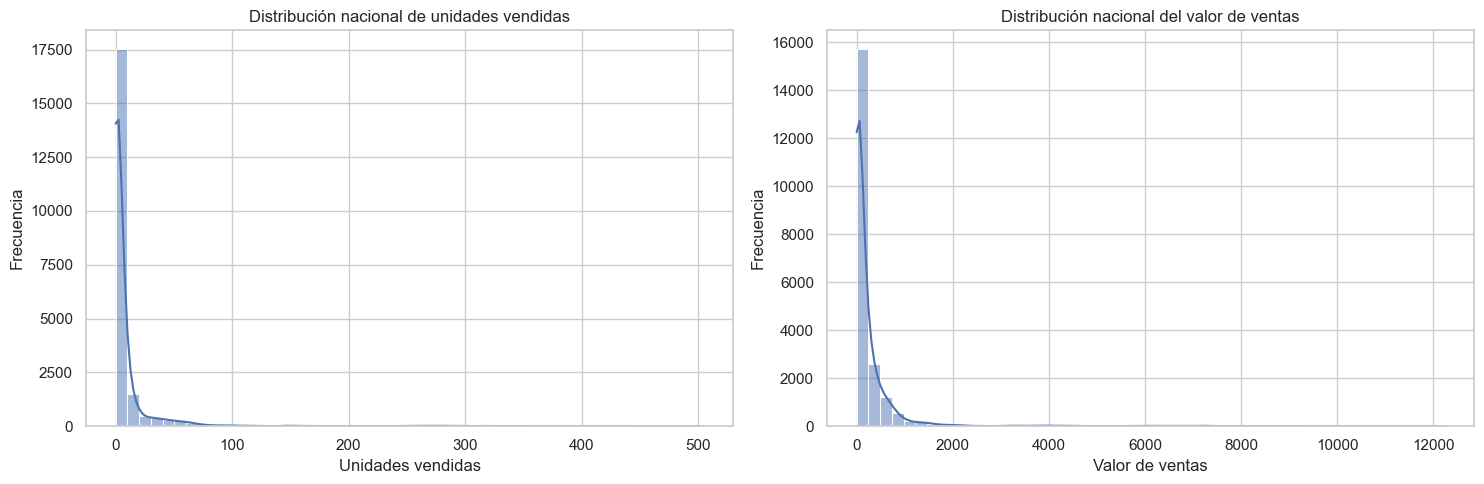

In [18]:

# Distribución nacional de unidades y valor de ventas

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=sales_nacional,
    x="TOTAL_UNIT_SALES",
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribución nacional de unidades vendidas")
axes[0].set_xlabel("Unidades vendidas")
axes[0].set_ylabel("Frecuencia")

sns.histplot(
    data=sales_nacional,
    x="TOTAL_VALUE_SALES",
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribución nacional del valor de ventas")
axes[1].set_xlabel("Valor de ventas")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()


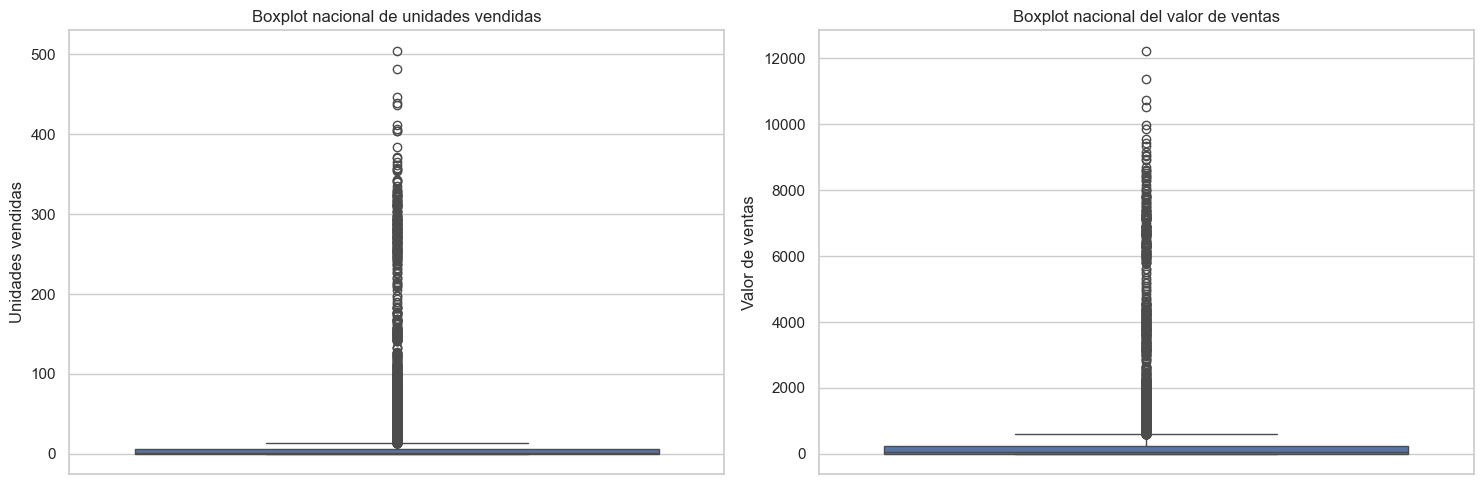

In [19]:

# Boxplots de las variables de ventas nacionales

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=sales_nacional,
    y="TOTAL_UNIT_SALES",
    ax=axes[0]
)

axes[0].set_title("Boxplot nacional de unidades vendidas")
axes[0].set_ylabel("Unidades vendidas")

sns.boxplot(
    data=sales_nacional,
    y="TOTAL_VALUE_SALES",
    ax=axes[1]
)

axes[1].set_title("Boxplot nacional del valor de ventas")
axes[1].set_ylabel("Valor de ventas")

plt.tight_layout()
plt.show()


In [20]:

# Identificación de valores atípicos en el consolidado nacional

resultados = []

for variable in ["TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES"]:

    Q1 = sales_nacional[variable].quantile(0.25)
    Q3 = sales_nacional[variable].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = sales_nacional[
        (sales_nacional[variable] < limite_inferior) |
        (sales_nacional[variable] > limite_superior)
    ]

    resultados.append({
        "Variable": variable,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Cantidad de outliers": len(outliers),
        "Porcentaje (%)": len(outliers) / len(sales_nacional) * 100
    })

resultados_outliers = pd.DataFrame(resultados)

display(resultados_outliers.round(2))


,Variable,Límite inferior,Límite superior,Cantidad de outliers,Porcentaje (%)
0,TOTAL_UNIT_SALES,-8.07,13.92,2566,12.22
1,TOTAL_VALUE_SALES,-355.26,608.87,2031,9.68



### Interpretación de valores atípicos

El análisis del consolidado nacional permitió identificar valores atípicos en las variables de ventas. Para las unidades vendidas se detectaron 2,566 registros, equivalentes al 12.22 % del total. En el valor de ventas se identificaron 2,031 registros, correspondientes al 9.68 %.

Estos resultados muestran que existen operaciones con valores considerablemente superiores al comportamiento habitual. Sin embargo, no deben considerarse errores automáticamente, ya que podrían corresponder a ventas reales de mayor volumen.

Se recomienda revisar estos registros para determinar su origen y evaluar su impacto en futuros análisis comerciales.


In [21]:

# Evolución semanal de las ventas nacionales

ventas_nacionales_tiempo = (
    sales_nacional
    .groupby("DATE", as_index=False)
    .agg(
        UNIDADES_VENDIDAS=("TOTAL_UNIT_SALES", "sum"),
        VALOR_VENTAS=("TOTAL_VALUE_SALES", "sum")
    )
    .sort_values("DATE")
)

print("Registros temporales:", len(ventas_nacionales_tiempo))

display(ventas_nacionales_tiempo.head(10))


Registros temporales: 80


,DATE,UNIDADES_VENDIDAS,VALOR_VENTAS
0,2022-01-09,2830.907,75769.458
1,2022-01-16,2843.072,73498.479
2,2022-01-23,2422.436,62675.664
3,2022-01-30,2396.793,61972.797
4,2022-02-06,2510.638,64920.868
5,2022-02-13,2220.314,58336.390
6,2022-02-20,2405.283,63123.878
7,2022-02-27,2326.093,60886.425
8,2022-03-06,2639.905,70808.648
9,2022-03-13,2252.844,61890.050


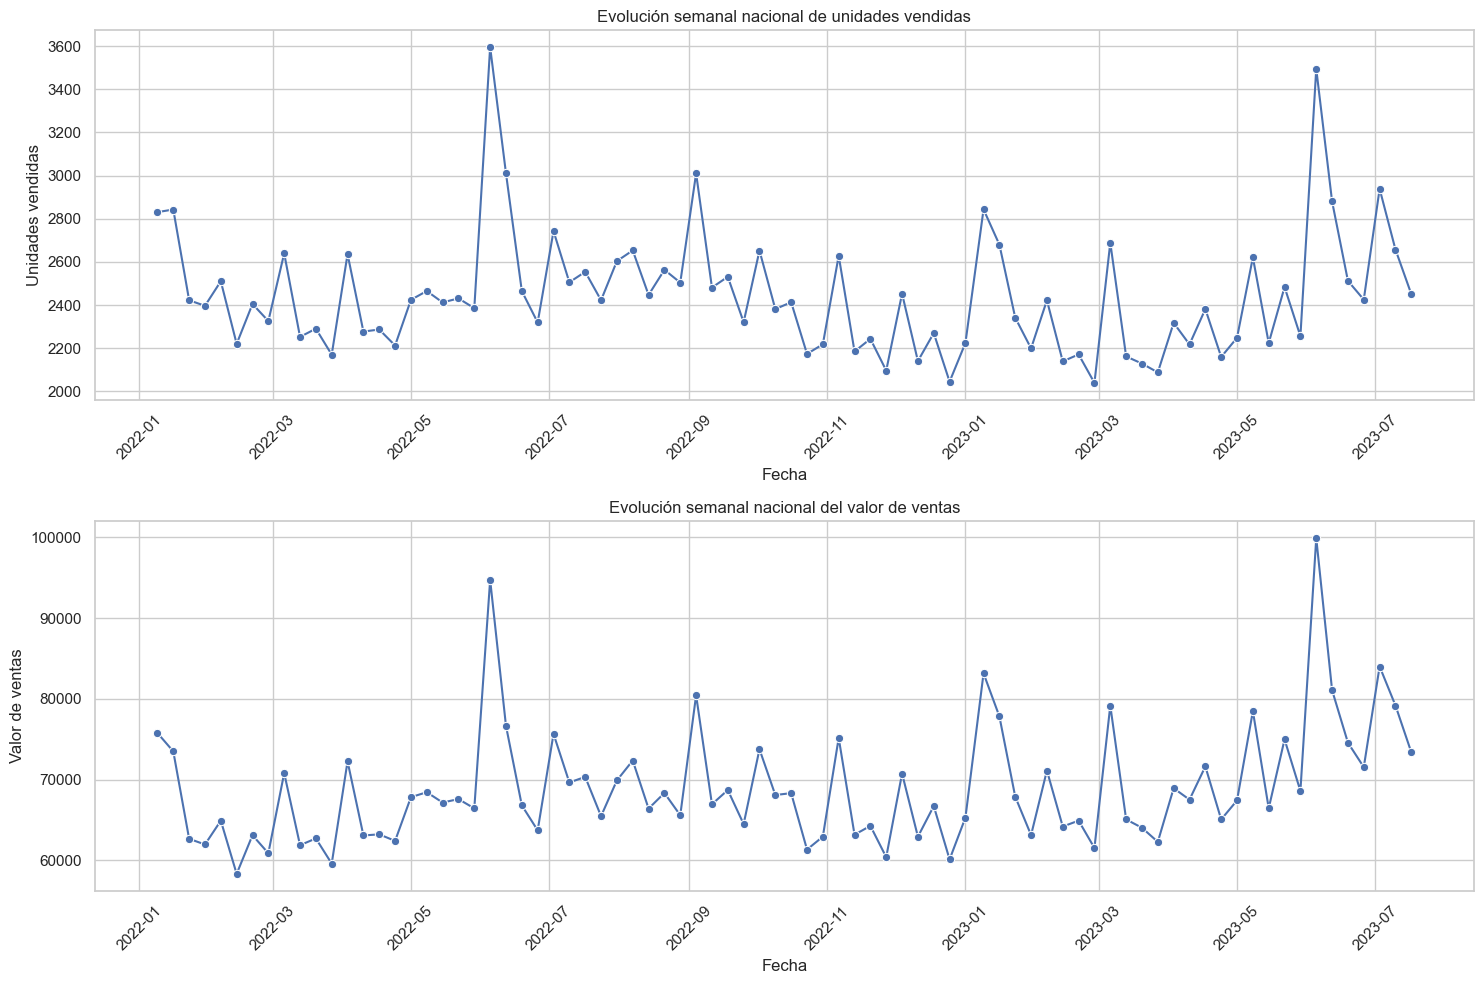

In [22]:

# Evolución semanal de las unidades vendidas y del valor de ventas

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Gráfica de unidades vendidas
sns.lineplot(
    data=ventas_nacionales_tiempo,
    x="DATE",
    y="UNIDADES_VENDIDAS",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Evolución semanal nacional de unidades vendidas")
axes[0].set_xlabel("Fecha")
axes[0].set_ylabel("Unidades vendidas")
axes[0].tick_params(axis="x", rotation=45)

# Gráfica del valor de ventas
sns.lineplot(
    data=ventas_nacionales_tiempo,
    x="DATE",
    y="VALOR_VENTAS",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Evolución semanal nacional del valor de ventas")
axes[1].set_xlabel("Fecha")
axes[1].set_ylabel("Valor de ventas")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



### Interpretación de las tendencias temporales

Las gráficas muestran que las ventas nacionales presentan fluctuaciones semanales durante el periodo comprendido entre enero de 2022 y julio de 2023.

Se identifican incrementos importantes en las unidades vendidas y en el valor de ventas, especialmente alrededor de junio de 2022 y junio de 2023. Este último periodo presenta uno de los picos más destacados del análisis.

El comportamiento de ambas variables es similar, lo que sugiere que los aumentos en las unidades vendidas están relacionados con incrementos en el valor de las ventas.

Se recomienda investigar los factores comerciales que pudieron influir en estas variaciones.


In [23]:

# Análisis de ventas por región (sin consolidado nacional)

ventas_region = (
    sales_detalle
    .groupby("REGION", as_index=False)
    .agg(
        TOTAL_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        TOTAL_VENTAS=("TOTAL_VALUE_SALES", "sum")
    )
    .sort_values("TOTAL_VENTAS", ascending=False)
)

display(ventas_region)

print("Número de regiones:", ventas_region["REGION"].nunique())


,REGION,TOTAL_UNIDADES,TOTAL_VENTAS
1,TOTAL AUTOS AREA 2,45319.916,1188796.150
4,TOTAL AUTOS AREA 5,36266.900,1153335.538
5,TOTAL AUTOS AREA 6,38585.222,983957.571
2,TOTAL AUTOS AREA 3,25896.054,803655.337
0,TOTAL AUTOS AREA 1,25791.933,714249.979
3,TOTAL AUTOS AREA 4,24020.149,677435.998


Número de regiones: 6


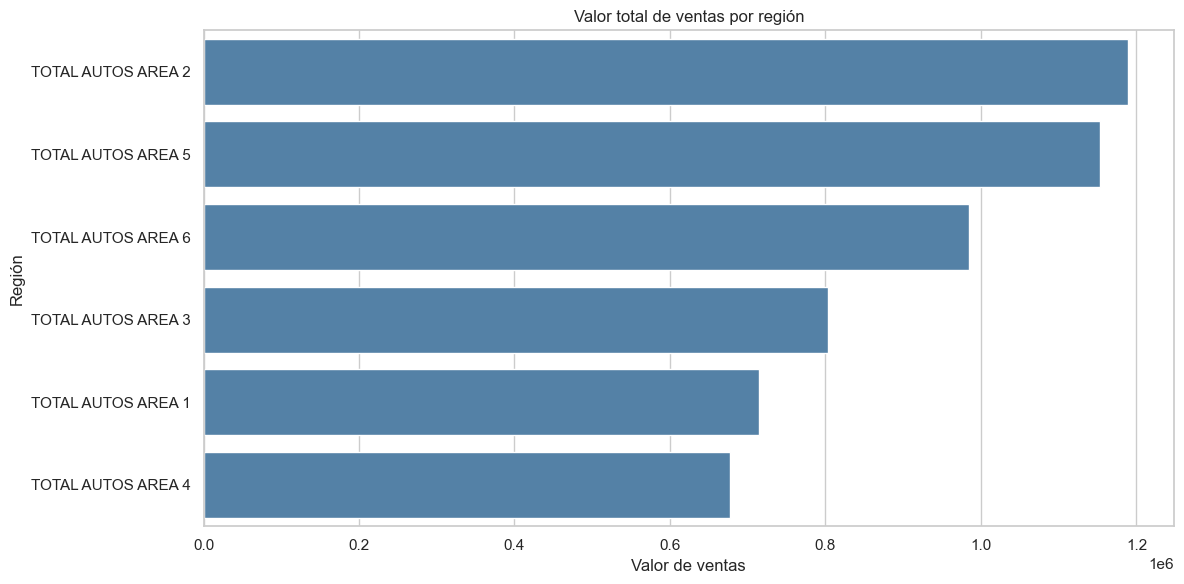

In [24]:


# Visualización del valor de ventas por región
# Se excluye el consolidado nacional

ventas_region_ordenadas = ventas_region.sort_values(
    "TOTAL_VENTAS",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=ventas_region_ordenadas,
    x="TOTAL_VENTAS",
    y="REGION",
    color="steelblue"
)

plt.title("Valor total de ventas por región")
plt.xlabel("Valor de ventas")
plt.ylabel("Región")

plt.tight_layout()

plt.savefig(
    "visualizaciones_eda/ventas_por_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



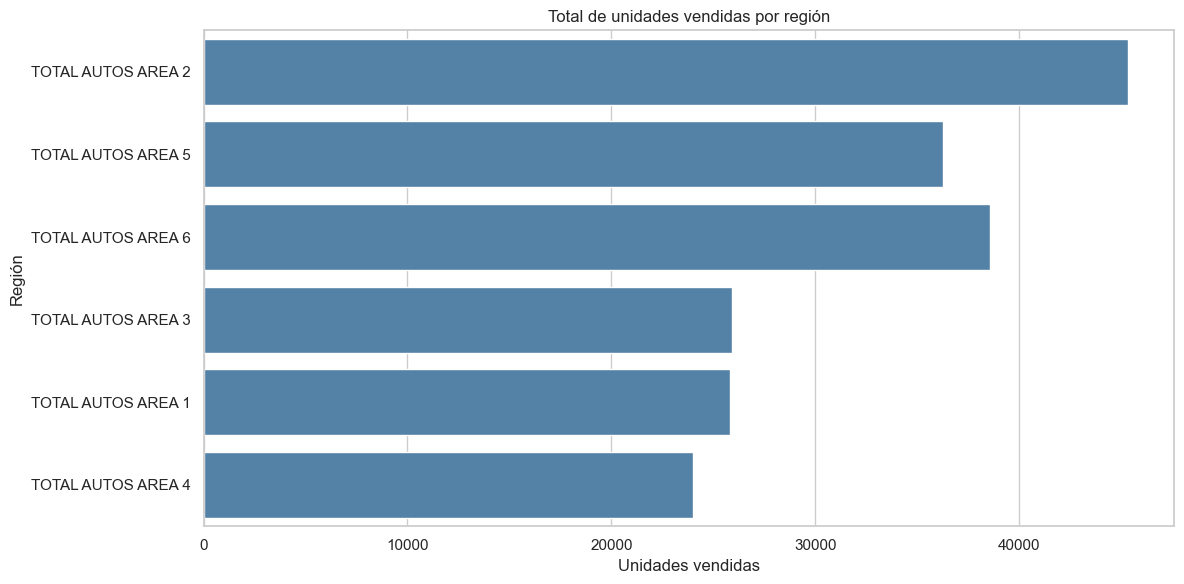

In [25]:

# Visualización de unidades vendidas por región
# Se excluye el consolidado nacional

plt.figure(figsize=(12, 6))

sns.barplot(
    data=ventas_region,
    x="TOTAL_UNIDADES",
    y="REGION",
    color="steelblue"
)

plt.title("Total de unidades vendidas por región")
plt.xlabel("Unidades vendidas")
plt.ylabel("Región")

plt.tight_layout()

plt.savefig(
    "visualizaciones_eda/unidades_por_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [26]:


# Análisis de ventas por marca
# Se excluye el consolidado nacional

ventas_marca = (
    sales_detalle
    .groupby("BRAND", as_index=False)
    .agg(
        TOTAL_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        TOTAL_VENTAS=("TOTAL_VALUE_SALES", "sum")
    )
)

# Seleccionar las 10 marcas con mayor valor de ventas

top_10_marcas = (
    ventas_marca
    .sort_values(
        by="TOTAL_VENTAS",
        ascending=False
    )
    .head(10)
)

display(top_10_marcas)



,BRAND,TOTAL_UNIDADES,TOTAL_VENTAS
4,CLORALEX,111650.338,2696809.337
23,VANISH,27666.486,1084144.857
6,CLOROX,23940.606,685875.935
2,BLANCATEL,10305.648,326242.020
17,OXI CLEAN,3039.688,218485.401
9,DR.BECKMANN,2614.674,139859.651
0,BANDERA,6061.551,134968.519
14,LOS PATITOS,3390.846,71372.852
3,CLARASOL,4910.567,70506.095
15,LYSOL,264.747,35278.683


,BRAND,TOTAL_UNIDADES,TOTAL_VENTAS
4,CLORALEX,111650.338,2696809.337
23,VANISH,27666.486,1084144.857
6,CLOROX,23940.606,685875.935
2,BLANCATEL,10305.648,326242.020
17,OXI CLEAN,3039.688,218485.401
9,DR.BECKMANN,2614.674,139859.651
0,BANDERA,6061.551,134968.519
14,LOS PATITOS,3390.846,71372.852
3,CLARASOL,4910.567,70506.095
15,LYSOL,264.747,35278.683


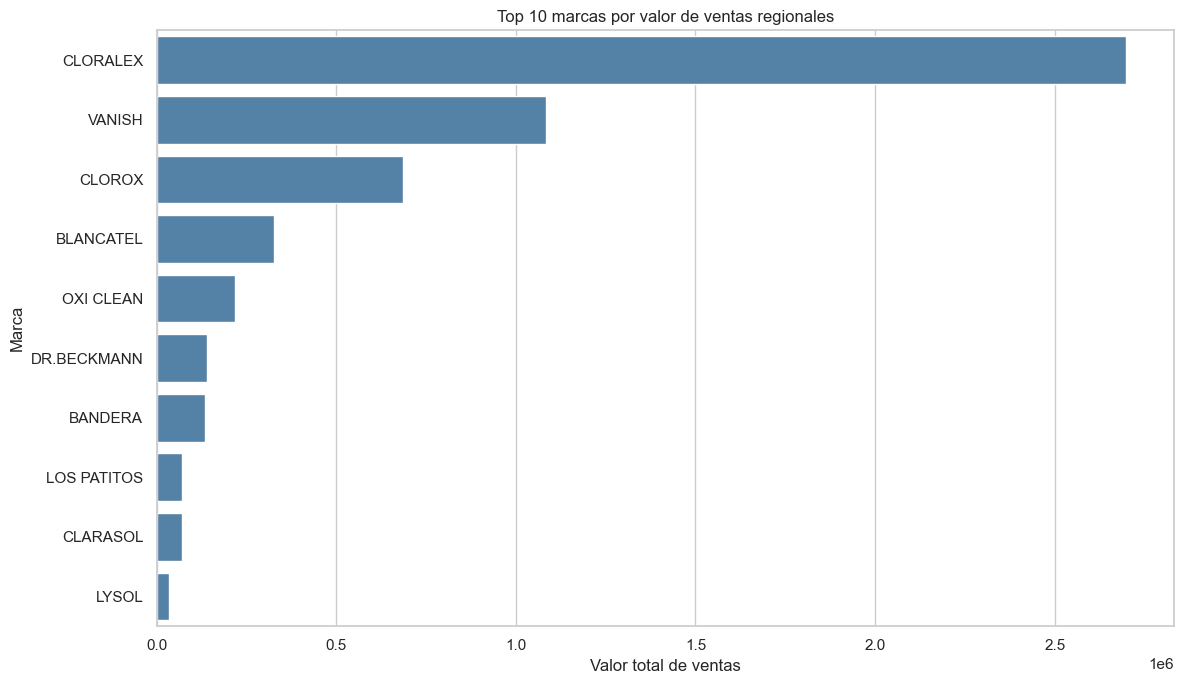

In [27]:

# Visualización de las 10 marcas con mayor valor de ventas
# Se excluye el consolidado nacional

ventas_marca = (
    sales_detalle.groupby("BRAND", as_index=False)
    .agg(
        TOTAL_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        TOTAL_VENTAS=("TOTAL_VALUE_SALES", "sum")
    )
)

top_10_marcas = (
    ventas_marca
    .sort_values("TOTAL_VENTAS", ascending=False)
    .head(10)
)

display(top_10_marcas)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_marcas,
    x="TOTAL_VENTAS",
    y="BRAND",
    color="steelblue"
)

plt.title("Top 10 marcas por valor de ventas regionales")
plt.xlabel("Valor total de ventas")
plt.ylabel("Marca")

plt.tight_layout()

plt.savefig(
    "visualizaciones_eda/top_10_marcas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [28]:


# Relacionar las ventas regionales con los nombres de las categorías

dim_category_merge = dim_category.rename(
    columns={
        "ID_CATEGORY": "CATEGORY_ID",
        "CATEGORY": "CATEGORY_NAME"
    }
)

sales_categoria = sales_detalle.merge(
    dim_category_merge,
    left_on="CATEGORY",
    right_on="CATEGORY_ID",
    how="left",
    validate="many_to_one"
)

# Calcular ventas por categoría

ventas_categoria = (
    sales_categoria.groupby("CATEGORY_NAME", as_index=False)
    .agg(
        TOTAL_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        TOTAL_VENTAS=("TOTAL_VALUE_SALES", "sum")
    )
    .sort_values("TOTAL_VENTAS", ascending=False)
)

display(ventas_categoria)



,CATEGORY_NAME,TOTAL_UNIDADES,TOTAL_VENTAS
0,FABRIC TREATMENT and SANIT\r\n,195880.174,5521430.573


In [29]:

# Revisar categorías originales

print("Categorías en DIM_CATEGORY:")
display(dim_category)

print("\nIdentificadores de categoría en DIM_PRODUCT:")
print(sorted(dim_product["CATEGORY"].dropna().unique()))

print("\nIdentificadores de categoría en ventas consolidadas:")
print(sorted(sales_eda["CATEGORY"].dropna().unique()))

print("\nCantidad de categorías encontradas:")
print(sales_categoria["CATEGORY_NAME"].nunique())

print("\nRegistros sin categoría relacionada:")
print(sales_categoria["CATEGORY_NAME"].isnull().sum())


Categorías en DIM_CATEGORY:


,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT\r\n
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC



Identificadores de categoría en DIM_PRODUCT:
[np.int64(1)]

Identificadores de categoría en ventas consolidadas:
[np.int64(1)]

Cantidad de categorías encontradas:
1

Registros sin categoría relacionada:
0


In [30]:

# Distribución de productos por categoría

print("Cantidad de productos por categoría:")
display(dim_product["CATEGORY"].value_counts(dropna=False))

print("\nCantidad de registros de ventas por categoría:")
display(sales_eda["CATEGORY"].value_counts(dropna=False))


Cantidad de productos por categoría:


CATEGORY
1    505
Name: count, dtype: int64


Cantidad de registros de ventas por categoría:


CATEGORY
1    122002
Name: count, dtype: int64

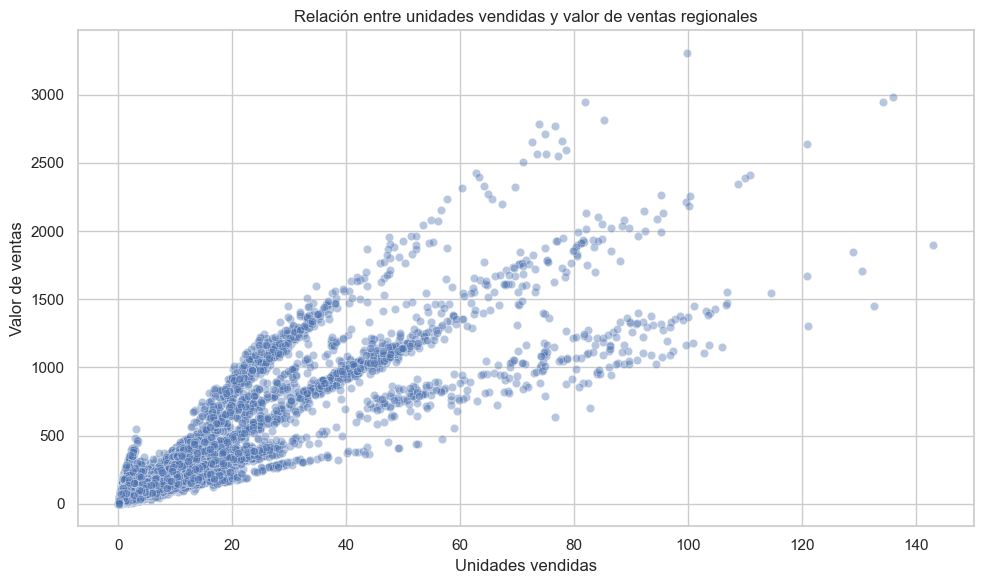

In [31]:


# Relación entre unidades vendidas y valor de ventas regionales

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sales_detalle,
    x="TOTAL_UNIT_SALES",
    y="TOTAL_VALUE_SALES",
    alpha=0.4
)

plt.title("Relación entre unidades vendidas y valor de ventas regionales")
plt.xlabel("Unidades vendidas")
plt.ylabel("Valor de ventas")

plt.tight_layout()

plt.savefig(
    "visualizaciones_eda/dispersion_ventas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [32]:

# Calcular la correlación entre unidades y valor de ventas regionales

correlacion_pearson = sales_detalle[
    ["TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES"]
].corr(method="pearson")

correlacion_spearman = sales_detalle[
    ["TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES"]
].corr(method="spearman")

print("Correlación de Pearson:")
display(correlacion_pearson)

print("\nCorrelación de Spearman:")
display(correlacion_spearman)



Correlación de Pearson:


,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
TOTAL_UNIT_SALES,1.000000,0.907334
TOTAL_VALUE_SALES,0.907334,1.000000



Correlación de Spearman:


,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
TOTAL_UNIT_SALES,1.000000,0.918682
TOTAL_VALUE_SALES,0.918682,1.000000



### Interpretación del análisis de correlación

El análisis de correlación permitió identificar una relación positiva muy fuerte entre las unidades vendidas y el valor de las ventas en las seis áreas regionales.

El coeficiente de Pearson fue de 0.907334, mientras que el coeficiente de Spearman fue de 0.918682. Ambos resultados indican que, generalmente, cuando aumenta la cantidad de unidades vendidas, también aumenta el valor de las ventas.

La similitud entre ambos coeficientes demuestra que esta relación se mantiene tanto desde una perspectiva lineal como desde una perspectiva basada en rangos.

Es importante señalar que la correlación no implica causalidad, pero proporciona información relevante para comprender el comportamiento comercial.


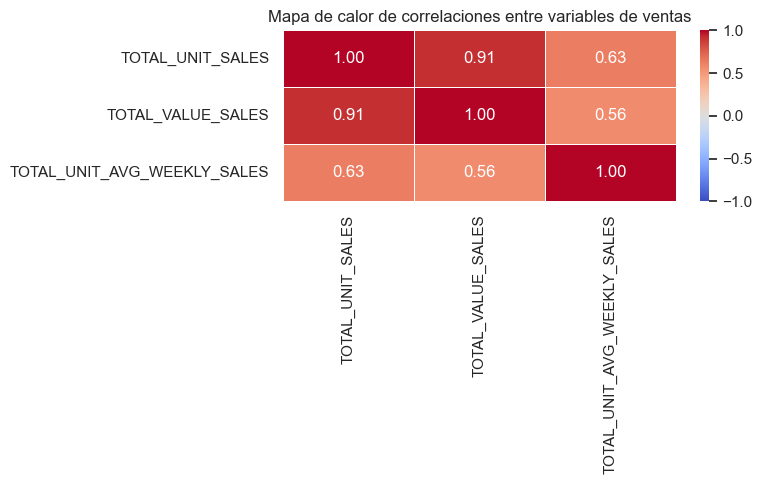

In [33]:

# Mapa de calor de correlaciones

plt.figure(figsize=(8, 5))

correlaciones = sales_detalle[
    ["TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES",
     "TOTAL_UNIT_AVG_WEEKLY_SALES"]
].corr()

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Mapa de calor de correlaciones entre variables de ventas")
plt.tight_layout()
plt.show()


In [34]:

# Crear carpeta para guardar las visualizaciones

import os

os.makedirs("visualizaciones_eda", exist_ok=True)

print("Carpeta creada correctamente.")


Carpeta creada correctamente.


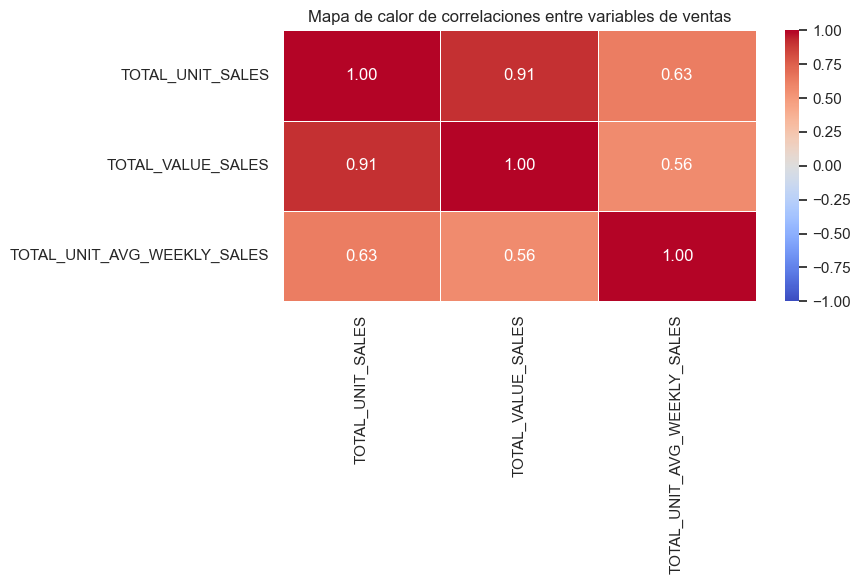

Mapa de calor guardado correctamente.


In [35]:

# Guardar mapa de calor en formato PNG

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Mapa de calor de correlaciones entre variables de ventas")
plt.tight_layout()

plt.savefig(
    "visualizaciones_eda/mapa_calor_correlaciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mapa de calor guardado correctamente.")


In [36]:

# Guardar las visualizaciones del análisis exploratorio

import os

os.makedirs("visualizaciones_eda", exist_ok=True)

# 1. Histogramas nacionales
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(sales_nacional["TOTAL_UNIT_SALES"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribución nacional de unidades vendidas")

sns.histplot(sales_nacional["TOTAL_VALUE_SALES"], bins=50, kde=True, ax=axes[1])
axes[1].set_title("Distribución nacional del valor de ventas")

plt.tight_layout()
fig.savefig("visualizaciones_eda/histogramas_ventas.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# 2. Boxplots nacionales
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(y=sales_nacional["TOTAL_UNIT_SALES"], ax=axes[0])
axes[0].set_title("Boxplot nacional de unidades vendidas")

sns.boxplot(y=sales_nacional["TOTAL_VALUE_SALES"], ax=axes[1])
axes[1].set_title("Boxplot nacional del valor de ventas")

plt.tight_layout()
fig.savefig("visualizaciones_eda/boxplots_ventas.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# 3. Tendencias temporales nacionales
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

axes[0].plot(ventas_nacionales_tiempo["DATE"], ventas_nacionales_tiempo["UNIDADES_VENDIDAS"])
axes[0].set_title("Evolución semanal nacional de unidades vendidas")

axes[1].plot(ventas_nacionales_tiempo["DATE"], ventas_nacionales_tiempo["VALOR_VENTAS"])
axes[1].set_title("Evolución semanal nacional del valor de ventas")

plt.tight_layout()
fig.savefig("visualizaciones_eda/tendencias_temporales.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# 4. Ventas regionales
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=ventas_region, x="TOTAL_VENTAS", y="REGION", ax=ax)
ax.set_title("Valor total de ventas por región")
plt.tight_layout()
fig.savefig("visualizaciones_eda/ventas_region.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# 5. Top 10 marcas regionales
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=top_10_marcas, x="TOTAL_VENTAS", y="BRAND", ax=ax)
ax.set_title("Top 10 marcas por valor de ventas regionales")
plt.tight_layout()
fig.savefig("visualizaciones_eda/top_10_marcas.png", dpi=300, bbox_inches="tight")
plt.close(fig)

# 6. Dispersión regional
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sales_detalle, x="TOTAL_UNIT_SALES", y="TOTAL_VALUE_SALES", alpha=0.4, ax=ax)
ax.set_title("Relación entre unidades vendidas y valor de ventas regionales")
plt.tight_layout()
fig.savefig("visualizaciones_eda/dispersion_ventas.png", dpi=300, bbox_inches="tight")
plt.close(fig)

print("Visualizaciones guardadas correctamente.")

Visualizaciones guardadas correctamente.


In [37]:

# Verificar las visualizaciones guardadas

archivos = os.listdir("visualizaciones_eda")

print("Visualizaciones encontradas:")
for archivo in archivos:
    print("✓", archivo)

print("\nTotal de imágenes:", len(archivos))


Visualizaciones encontradas:
✓ boxplots_ventas.png
✓ dispersion_ventas.png
✓ histogramas_ventas.png
✓ mapa_calor_correlaciones.png
✓ tendencias_temporales.png
✓ top_10_marcas.png
✓ unidades_por_region.png
✓ ventas_por_region.png
✓ ventas_region.png

Total de imágenes: 9


## Conclusión final

El análisis exploratorio de datos permitió conocer el comportamiento de las ventas durante el periodo comprendido entre enero de 2022 y julio de 2023. Mediante el uso de Python, Pandas, Matplotlib y Seaborn se analizaron las unidades vendidas, el valor de las ventas, las tendencias temporales, las regiones, las marcas y la relación entre las principales variables comerciales.

Los resultados nacionales muestran que las ventas presentan una distribución asimétrica positiva, con una concentración de registros en valores bajos y la presencia de valores atípicos. En el consolidado nacional se identificaron 2,566 registros atípicos en unidades vendidas, equivalentes al 12.22 %, y 2,031 en valor de ventas, correspondientes al 9.68 %. Estos registros deben revisarse para determinar si representan operaciones comerciales extraordinarias o posibles inconsistencias.

En el análisis temporal se observaron fluctuaciones semanales durante todo el periodo, con incrementos importantes alrededor de junio de 2022 y junio de 2023. Esto demuestra que el comportamiento de las ventas no fue completamente constante.

En cuanto al desempeño regional, el AREA 2 presentó el mayor volumen de unidades vendidas y el mayor valor de ventas entre las seis áreas analizadas. En el análisis de marcas de los registros regionales, CLORALEX destacó como la marca con mayor valor de ventas, seguida de VANISH y CLOROX.

También se identificó una correlación positiva muy fuerte entre las unidades vendidas y el valor de las ventas en los registros regionales, con un coeficiente de Pearson de 0.907334 y uno de Spearman de 0.918682. Esto indica que, generalmente, cuando aumenta la cantidad de unidades vendidas, también aumenta el valor de las ventas.

Respecto a las categorías, aunque el catálogo general contiene cinco categorías, los productos y registros de ventas analizados se relacionaron únicamente con la categoría 1. Por esta razón, no fue posible realizar una comparación completa entre todas las categorías disponibles.

## Recomendaciones

- Investigar los valores atípicos para determinar su origen y validar su comportamiento comercial.
- Analizar las fluctuaciones semanales para identificar los factores que influyen en los cambios de ventas.
- Dar seguimiento al desempeño de las marcas CLORALEX, VANISH y CLOROX.
- Estudiar las estrategias comerciales del AREA 2 para identificar buenas prácticas que puedan aplicarse en otras regiones.
- Mejorar la información disponible sobre las categorías y atributos de los productos.
- Continuar realizando análisis periódicos para apoyar la toma de decisiones comerciales.

## Conclusión general

Este proyecto permitió aplicar técnicas de análisis exploratorio y visualización de datos para transformar información de ventas en resultados comprensibles y útiles. Los hallazgos obtenidos proporcionan una base para identificar oportunidades de mejora, evaluar el desempeño comercial y respaldar futuras decisiones estratégicas mediante el análisis de datos.